In [16]:
import xarray as xr
import numpy as np
import pdb
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pylab import *
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as mticker
from netCDF4 import Dataset
import pandas as pd

In [2]:
path = '/nfs/scistore16/mullegrp/acasalla/MPI-C/Results/'

ds_tnf_mon = xr.open_dataset(f'{path}TOTALS_No_FIRES/PM2_5_TOTALS_No_FIRES.nc')

In [3]:
ds_tot_mon= xr.open_dataset(f'{path}TOTALS/PM2_5_TOTALS.nc')
ds_agri_mon = xr.open_dataset(f'{path}Agriculture/PM2_5_Agriculture.nc')
ds_road_mon = xr.open_dataset(f'{path}Road_Transport/PM2_5_Road_Transport.nc')
ds_ort_mon = xr.open_dataset(f'{path}Off_Road_Transport/PM2_5_Off_Road_Transport.nc')
ds_indu_mon = xr.open_dataset(f'{path}Industry/PM2_5_Industry.nc')
ds_tnaf_mon = xr.open_dataset(f'{path}TOTALS_No_ANTHRO_FIRES/PM2_5_TOTALS_No_ANTHRO_FIRES.nc')
ds_wast_mon = xr.open_dataset(f'{path}Waste/PM2_5_Waste.nc')
ds_shi_mon = xr.open_dataset(f'{path}Shipping/PM2_5_Shipping.nc')
ds_ene_mon = xr.open_dataset(f'{path}Energy_Use/PM2_5_Energy_Use.nc')

Agriculture
Road Transport
Industry
All sectors with fires
Waste
Off Road Transport
Shipping
Energy


Text(0.5, 0.95, 'Mean for between Mar 24 to Abr 10')

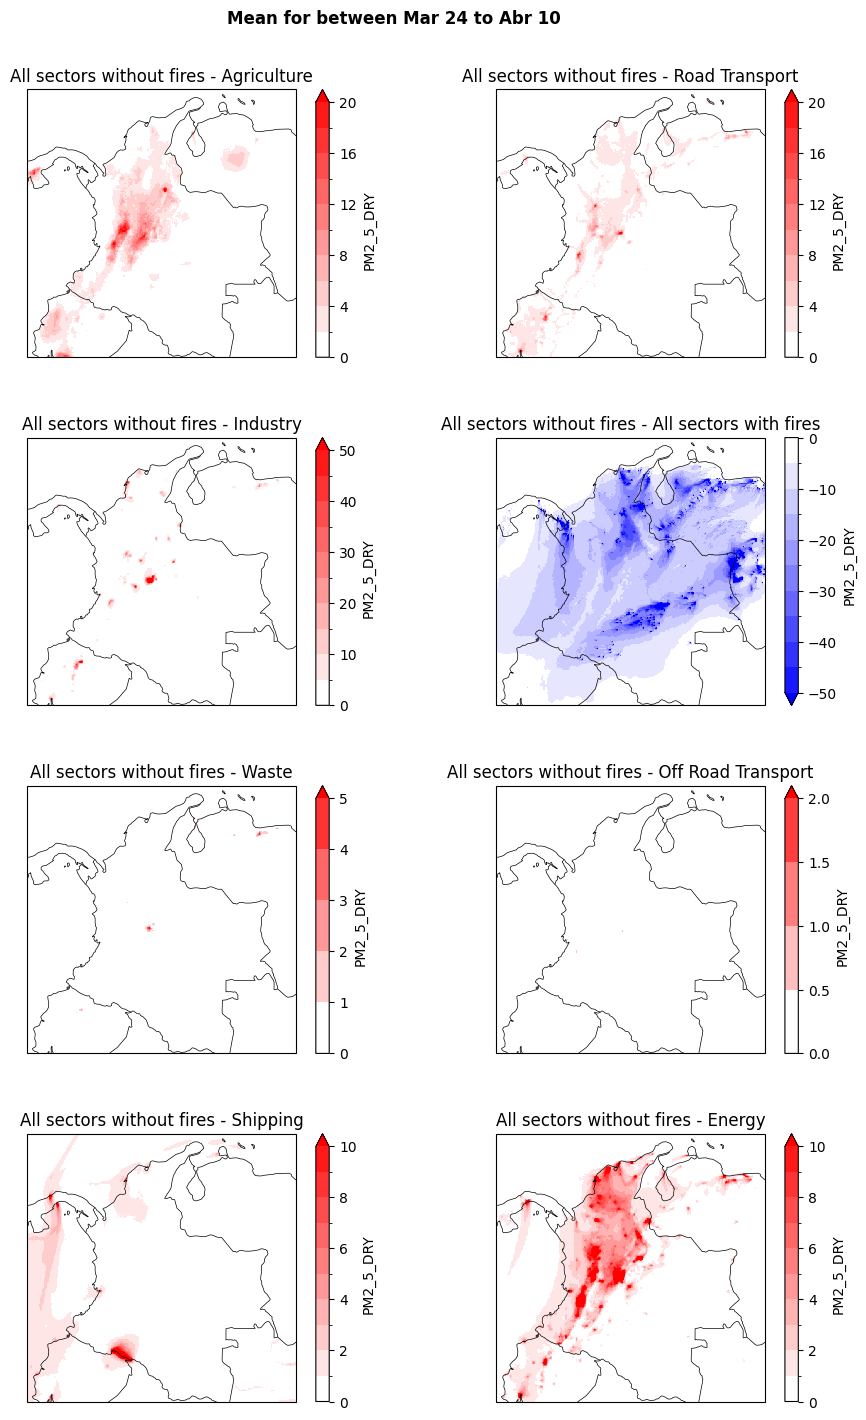

In [8]:
ds_s = [ds_agri_mon, ds_road_mon, ds_indu_mon, ds_tot_mon, ds_wast_mon, ds_ort_mon, ds_shi_mon, ds_ene_mon]

names = ['Agriculture', 'Road Transport', 'Industry', 'All sectors with fires', 'Waste', 'Off Road Transport', 'Shipping', 'Energy']
ranges = [np.arange(0,20.1,2), np.arange(0,20.1,2), np.arange(0,50.1,5), np.arange(-50,0.1,5), np.arange(0,5.1,1), np.arange(0,2.1,0.5), np.arange(0,10.1,1), np.arange(0,10.1,1)]
cmap = LinearSegmentedColormap.from_list('', ['white','red'])
cmap_r = LinearSegmentedColormap.from_list('', ['blue','white'])
colors = [cmap]*3 + [cmap_r] + [cmap]*4
ext = ['max']*3 + ['min'] + ['max']*4


fig = plt.figure(figsize=(10,16))
gs = GridSpec(4,2,left = 0.09, right = 0.95, hspace=0.3, wspace=0.2, top = 0.9, bottom = 0.08)

for i,ds in enumerate(ds_s):
    print(names[i])
    ax = plt.subplot(gs[i], projection=ccrs.PlateCarree())
    diff = ds_tnf_mon.PM2_5_DRY[2000:2200,:,:].mean('XTIME') - ds.PM2_5_DRY[2000:2200,:,:].mean('XTIME')
    diff.plot(levels = ranges[i], cmap = colors[i], extend = ext[i], x="XLONG", y="XLAT")
    plt.title(f'All sectors without fires - {names[i]}')
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
plt.suptitle('Mean for between Mar 24 to Abr 10', y = 0.95, fontweight = 'bold', fontsize = 12)

## Yearmeans!

In [30]:
ds_tnf_mon = xr.open_dataset(f'{path}TOTALS_No_FIRES/PM2_5_TOTALS_No_FIRES_ymean.nc')
ds_tot_mon= xr.open_dataset(f'{path}TOTALS/PM2_5_TOTALS_ymonmean.nc')
ds_tot_mon=ds_tot_mon.mean(dim='XTIME')
ds_agri_mon = xr.open_dataset(f'{path}Agriculture/PM2_5_Agriculture_ymean.nc')
ds_avi_mon = xr.open_dataset(f'{path}Aviation/PM2_5_Aviation_ymean.nc')
ds_road_mon = xr.open_dataset(f'{path}Road_Transport/PM2_5_Road_Transport_ymean.nc')
ds_ort_mon = xr.open_dataset(f'{path}Off_Road_Transport/PM2_5_Off_Road_Transport_ymean.nc')
ds_indu_mon = xr.open_dataset(f'{path}Industry/PM2_5_Industry_ymean.nc')
ds_tnaf_mon = xr.open_dataset(f'{path}TOTALS_No_ANTHRO_FIRES/PM2_5_TOTALS_No_ANTHRO_FIRES_ymean.nc')
ds_wast_mon = xr.open_dataset(f'{path}Waste/PM2_5_Waste_ymean.nc')
ds_shi_mon = xr.open_dataset(f'{path}Shipping/PM2_5_Shipping_ymean.nc')
ds_ene_mon = xr.open_dataset(f'{path}Energy_Use/PM2_5_Energy_Use_ymean.nc')

In [14]:
##Read the topography
path_top = '/nfs/scistore16/mullegrp/acasalla/MPI-C/'
np.bool = np.bool_
crs = ccrs.PlateCarree()
topo = f'{path_top}GMRTv3_6_20190709topo.grd'
vart = Dataset(topo, mode='r')
xtopo=np.arange(vart.variables['x_range'][0],vart.variables['x_range'][1]+0.5*vart.variables['spacing'][0],
                vart.variables['spacing'][0])
ytopo=np.arange(vart.variables['y_range'][0],vart.variables['y_range'][1]+0.5*vart.variables['spacing'][1],
                vart.variables['spacing'][1])
xt0,yt0=np.meshgrid(xtopo,ytopo)
z = vart.variables['z'][:]
z = np.reshape(z, xt0.shape)[::-1,:]

## Shapes
world = f'{path_top}World_Countries/World_Countries.shp'
col = f'{path_top}World_Countries/COL_no_dptos.shp'
dept = f'{path_top}World_Countries/GDBIDEAM_departamentos.shp'
muni = f'{path_top}World_Countries/mpio/mpio.shp'

In [19]:
#### This is to get the cities with data
def get_coord(df,cities):
    '''Here we get the coordinates for each of the cities we want depending on the pollutants we need'''
    city_coord = {'Ciudad':[],'Lat':[],'Lon':[]}
    for city in cities.Ciudades.unique():
        city_coord['Ciudad'].append(city)
        city_coord['Lat'].append(df[df.CIUDAD == city].LATITUD.mean())
        city_coord['Lon'].append(df[df.CIUDAD == city].LONGITUD.mean())
    coords = pd.DataFrame.from_dict(city_coord)
    return(coords)

cities = pd.DataFrame()
pollutants = ['PM25','O3']
tmp = np.array([])

for pollu in pollutants:
    df_tmp = pd.read_csv(f'{path_top}Datos_estaciones/Pollutant_trend_data/Hourmean/{pollu}_hourmean_Colombia.csv', 
                      parse_dates = True, index_col = 0)
    tmp = np.append(tmp,df_tmp.columns.values)

cities['Ciudades'] = tmp

#### Lets get the lat and lon of the cities with data
df_tmp = pd.read_csv(f'{path_top}Datos_estaciones/catalogo_estaciones_con_ciudades_Colombia.csv', encoding = 'latin-1')
coord = get_coord(df_tmp,cities)

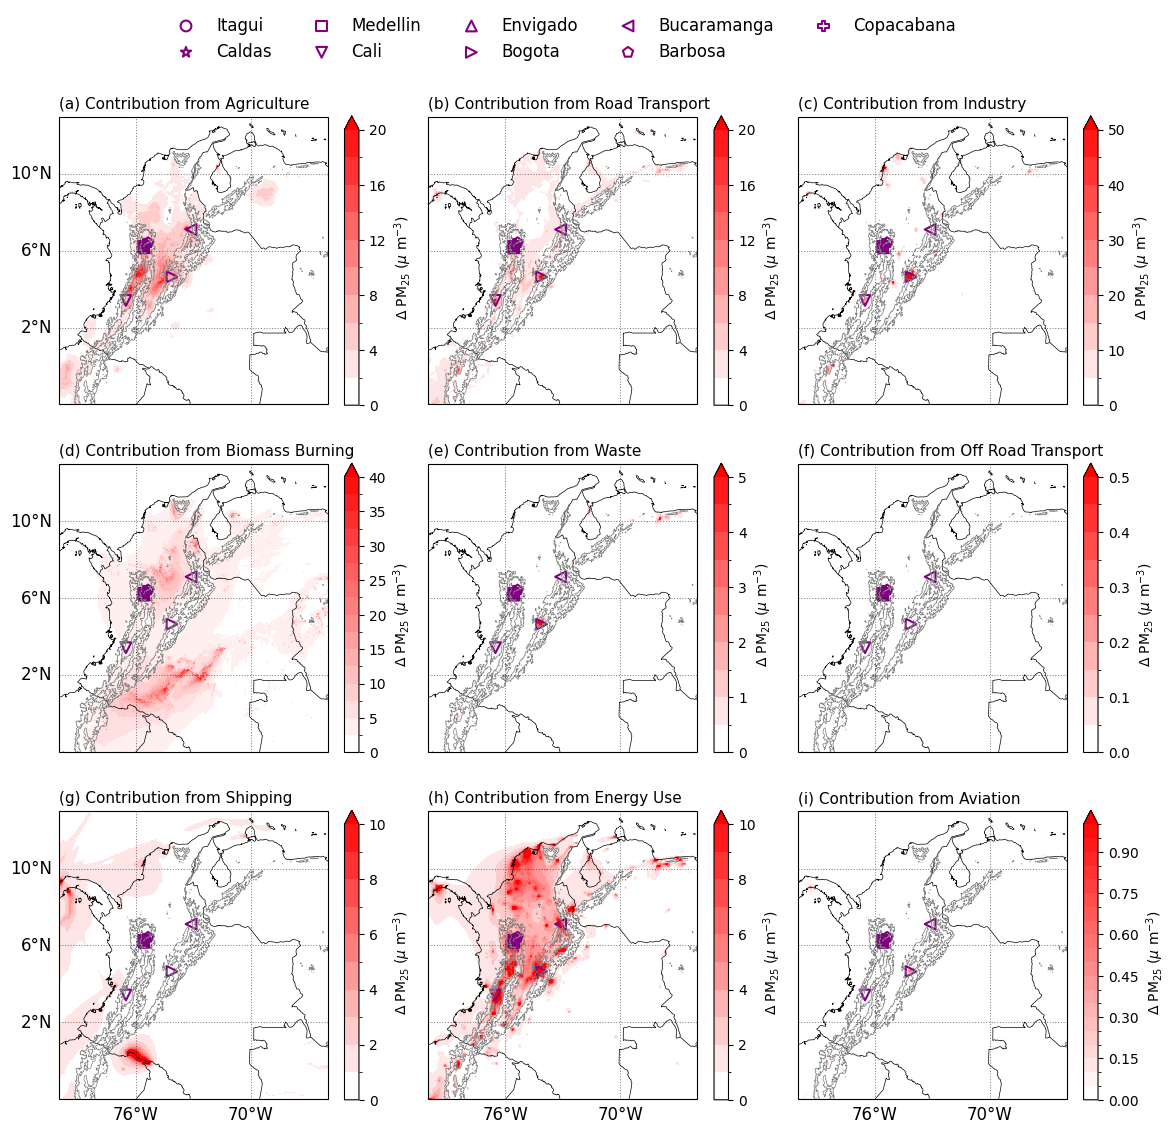

In [39]:
ds_s = [ds_agri_mon, ds_road_mon, ds_indu_mon, ds_tot_mon, ds_wast_mon, ds_ort_mon, ds_shi_mon, ds_ene_mon, ds_avi_mon]
markers = ['o','*','s','v','^','>','<','p','P','X','D','H','d']
mc = ['purple']*9

names = ['Agriculture', 'Road Transport', 'Industry', 'Biomass Burning', 'Waste', 'Off Road Transport', 'Shipping', 'Energy Use', 'Aviation']
#ranges = [np.arange(0,20.1,2), np.arange(0,20.1,2), np.arange(0,50.1,5), np.arange(-40,0.1,2.5), np.arange(0,5.1,0.5), np.arange(0,0.51,0.05), np.arange(0,10.1,1), np.arange(0,10.1,1)]
ranges = [np.arange(0,20.1,2), np.arange(0,20.1,2), np.arange(0,50.1,5), np.arange(0,40.1,2.5), np.arange(0,5.1,0.5), np.arange(0,0.51,0.05), np.arange(0,10.1,1), np.arange(0,10.1,1), np.arange(0,1.01,0.05)]
cmap = LinearSegmentedColormap.from_list('', ['white','red'])
cmap_r = LinearSegmentedColormap.from_list('', ['blue','white'])
colors = [cmap]*3 + [cmap] + [cmap]*5
ext = ['max']*3 + ['max'] + ['max']*5
titulo = ['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)','(i)']
crs = ccrs.PlateCarree()

fig = plt.figure(figsize=(12.5,12))
gs = GridSpec(3,3,left = 0.09, right = 0.95, hspace=0.2, wspace=0.1, top = 0.9, bottom = 0.08)

for i,ds in enumerate(ds_s):
    #print(names[i])
    ax = plt.subplot(gs[i], projection=ccrs.PlateCarree())
    if names[i] == 'Biomass Burning':
        diff = ds.PM2_5_DRY[:,:] - ds_tnf_mon.PM2_5_DRY[:,:] 
    else:
        diff = ds_tnf_mon.PM2_5_DRY[:,:] - ds.PM2_5_DRY[:,:]
    diff.plot(levels = ranges[i], cmap = colors[i], extend = ext[i], x="XLONG", y="XLAT", cbar_kwargs={'label': '$\Delta$ PM$_{25}$ ($\mu$ m$^{-3}$)'})

    curvas = plt.contour(xt0, yt0, z, levels = np.arange(1500,3001,1500),colors = 'grey', 
                         linewidths = 0.5)
    ax.set_extent([-66,-80,-2,13])
    plt.title(f'{titulo[i]} Contribution from {names[i]}', fontsize = 11, loc = 'left')
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    gl = ax.gridlines(crs = crs, draw_labels = True, linewidth = 0.75, color='k', 
                      alpha = 0.5, linestyle = ':')
    gl.xlocator = mticker.FixedLocator([-76, -70]) 
    gl.ylocator = mticker.FixedLocator([2, 6, 10])
    gl.xlabel_style = {'size': 12}; gl.ylabel_style = {'size': 12}
    if i == 0 or i == 3:
        gl.right_labels = False; gl.bottom_labels = False; gl.top_labels = False
    if i == 1 or i == 2 or i == 4 or i == 5:
        gl.right_labels = False; gl.bottom_labels = False; gl.top_labels = False; gl.left_labels = False
    if i == 6:
        gl.right_labels = False; gl.top_labels = False
    if i == 7 or i == 8:
        gl.right_labels = False; gl.top_labels = False; gl.left_labels = False

    for j,city in enumerate(coord.Ciudad.values[:-4]):
        plt.scatter(coord[coord.Ciudad == city].Lon.values, coord[coord.Ciudad == city].Lat.values,
                    label = city, marker = markers[j], s = 60, edgecolor = mc[j], facecolors = "None", 
                    linewidth = 1.5)
    if i == 1:
        plt.legend(frameon=False, ncol = 5, bbox_to_anchor = (0.5,1.4), loc = 'upper center', fontsize = 12)

plt.savefig(f'../Figures/Contribution_sector.jpg', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'../Figures/Contribution_sector.pdf', bbox_inches = 'tight', dpi = 300)